# Notebook 2 — Clasificación multiclase

Predecimos la situación final del estudiante (`abandono`, `matriculado`,
`graduado`) usando tres modelos de clasificación supervisada.

La lógica está en `src/clasificacion.py`; aquí orquestamos las llamadas,
visualizamos resultados y extraemos conclusiones.

## Modelos

- **KNN**
- **Regresión Logística (ElasticNet)** — modelo lineal con regularización
  L1+L2 y `class_weight='balanced'`
- **Random Forest** — no lineal, robusto a multicolinealidad,
  interpretable vía `feature_importances_`.

## Métrica principal: F1 macro

Las clases están desbalanceadas (graduado ~50 %, abandono ~32 %, matriculado
~18 %). El accuracy sería engañoso porque un clasificador que ignorara
`matriculado` aún así mantener buena precisión. El **F1 macro**
(promedio no ponderado del F1 por clase) penaliza explícitamente ignorar
clases minoritarias.

## 0. Configuración

In [18]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import clasificacion
from configuracion import (
    CLASIFICACION_TRAIN, CLASIFICACION_TEST,
    CONFUSION_PREFIX, FEATURE_IMPORTANCE_CLF,
    RESUMEN_CLASIFICACION, PREDICCIONES_CLASIFICACION,
    RESULTS_DIR,
)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print(f'Train: {CLASIFICACION_TRAIN}')
print(f'Test:  {CLASIFICACION_TEST}')

Train: C:\Users\mb6ja\Downloads\proyecto\data\processed\datos_limpios_clasificacion_train.csv
Test:  C:\Users\mb6ja\Downloads\proyecto\data\processed\datos_limpios_clasificacion_test.csv


## 1. Carga de datos

Leemos los CSVs producidos por el notebook de preprocesado, aplicamos un
shuffle de seguridad al train y separamos features/target.

In [19]:
X_train, y_train, X_test, y_test = clasificacion.cargar_datos(str(CLASIFICACION_TRAIN), str(CLASIFICACION_TEST))

print(f'Train: {X_train.shape[0]} registros × {X_train.shape[1]} features')
print(f'Test:  {X_test.shape[0]} registros')
print(f'\nDistribución del target en train:')
print(y_train.value_counts().sort_index())
print(f'\nCodificación: 0=abandono, 1=matriculado, 2=graduado')

Train: 3479 registros × 35 features
Test:  870 registros

Distribución del target en train:
objetivo
0    1121
1     629
2    1729
Name: count, dtype: int64

Codificación: 0=abandono, 1=matriculado, 2=graduado


## 2. Preprocesador

Definimos un `ColumnTransformer` que contiene dos transformaciones:

- **`StandardScaler`** sobre las variables numéricas — imprescindible para KNN y la
  regresión logística regularizada.
- **`OneHotEncoder`** sobre las categóricas con `handle_unknown='ignore'`
  para no fallar si en test aparece alguna categoría no vista.

Ir dentro de un `Pipeline` asegura que estas transformaciones se
**ajustan sólo con el fold de entrenamiento** en cada iteración de la
validación cruzada, evitando leakage del fold de validación.

In [20]:
preprocesador = clasificacion.construir_preprocesador(X_train)
cols_num = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
cols_cat = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
print(f'Numéricas   ({len(cols_num)}): {cols_num}')
print(f'\nCategóricas ({len(cols_cat)}): {cols_cat}')

Numéricas   (19): ['orden_solicitud', 'nota_cualificacion_previa', 'nota_admision', 'edad_al_matricularse', 'asignaturas_1sem_convalidadas', 'asignaturas_1sem_matriculadas', 'asignaturas_1sem_evaluadas', 'asignaturas_1sem_aprobadas', 'nota_media_1sem', 'asignaturas_1sem_sin_evaluacion', 'asignaturas_2sem_convalidadas', 'asignaturas_2sem_matriculadas', 'asignaturas_2sem_evaluadas', 'asignaturas_2sem_aprobadas', 'nota_media_2sem', 'asignaturas_2sem_sin_evaluacion', 'tasa_desempleo', 'tasa_inflacion', 'pib']

Categóricas (16): ['estado_civil', 'modo_solicitud', 'curso', 'asistencia_diurna_vespertina', 'cualificacion_previa', 'cualificacion_madre', 'cualificacion_padre', 'ocupacion_madre', 'ocupacion_padre', 'desplazado', 'necesidades_educativas_especiales', 'deudor', 'matricula_al_dia', 'genero', 'becado', 'internacional']


## 3. Definición de modelos y grids

Para cada modelo definimos un espacio de hiperparámetros. La
búsqueda con GridSearchCV y 5-fold estratificado (para mantener la proporción de clases en cada fold) selecciona la
combinación que maximiza el F1 macro en validación.

In [21]:
modelos = clasificacion.definir_modelos_y_grids(preprocesador)
for nombre, (_, grid) in modelos.items():
    n_combos = int(np.prod([len(v) for v in grid.values()])) if grid else 1
    print(f'{nombre:22s}{n_combos:3d} combinaciones')

KNN                    28 combinaciones
LogisticRegression     12 combinaciones
RandomForest           36 combinaciones


## 4. Entrenamiento con validación cruzada

Ejecutamos GridSearchCV para cada modelo con `StratifiedKFold(5)`. Por cada combinación
de hiperparámetros se entrenan 5 modelos, por lo que esta celda puede
tardar varios minutos.

In [22]:
resultados = clasificacion.entrenar_modelos(modelos, X_train, y_train, verbose=0)


  Entrenando: KNN
  Mejor F1 macro (CV): 0.6064
  Mejores params:      {'clf__metric': 'euclidean', 'clf__n_neighbors': 5, 'clf__weights': 'uniform'}

  Entrenando: LogisticRegression
  Mejor F1 macro (CV): 0.7188
  Mejores params:      {'clf__C': 0.1, 'clf__l1_ratio': 0.0}

  Entrenando: RandomForest
  Mejor F1 macro (CV): 0.7120
  Mejores params:      {'clf__max_depth': 20, 'clf__min_samples_leaf': 3, 'clf__n_estimators': 300}


## 5. Evaluación en test

Con los mejores hiperparámetros elegidos vía CV, evaluamos cada modelo en el
conjunto de test (nunca visto hasta ahora).


  KNN  |  F1 macro test = 0.6192
              precision    recall  f1-score   support

    abandono       0.74      0.70      0.72       280
 matriculado       0.43      0.28      0.34       157
    graduado       0.74      0.87      0.80       433

    accuracy                           0.71       870
   macro avg       0.64      0.61      0.62       870
weighted avg       0.69      0.71      0.69       870


  LogisticRegression  |  F1 macro test = 0.7103
              precision    recall  f1-score   support

    abandono       0.81      0.72      0.76       280
 matriculado       0.45      0.65      0.53       157
    graduado       0.88      0.80      0.84       433

    accuracy                           0.75       870
   macro avg       0.71      0.72      0.71       870
weighted avg       0.78      0.75      0.76       870


  RandomForest  |  F1 macro test = 0.7220
              precision    recall  f1-score   support

    abandono       0.79      0.76      0.77       280
 ma

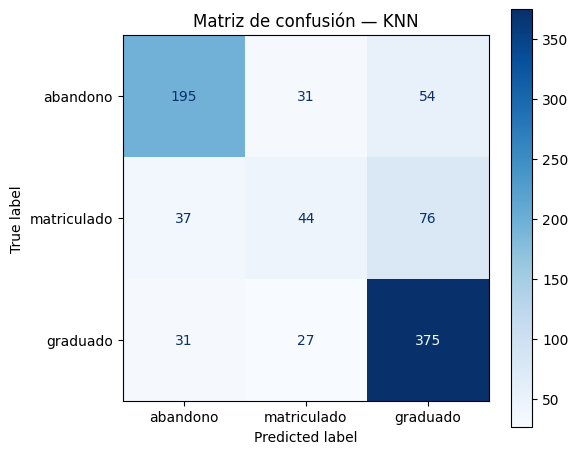

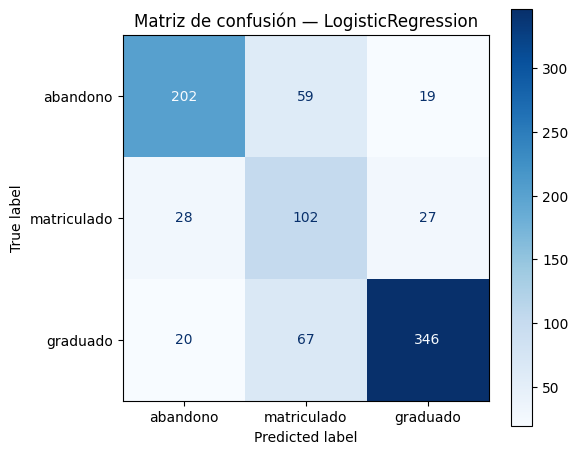

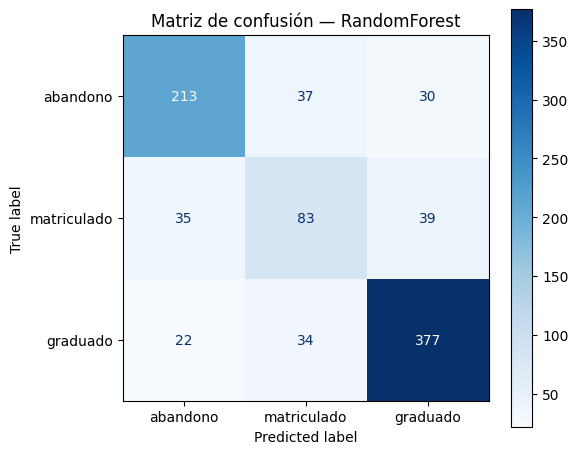

In [23]:
labels = sorted(y_train.unique())  # [0, 1, 2]
nombres_clases = ['abandono', 'matriculado', 'graduado']

df_resumen, figs_cm = clasificacion.evaluar_en_test(
    resultados, X_test, y_test,
    labels=labels,
    nombres_clases=nombres_clases,
    guardar_figs=True,
    path_prefix_cm=str(CONFUSION_PREFIX),
    path_resumen_csv=str(RESUMEN_CLASIFICACION))

### 5.1 Tabla comparativa

In [24]:
df_resumen.sort_values('f1_macro_test', ascending=False)

,modelo,f1_macro_cv,f1_macro_test,mejores_params
2,RandomForest,0.712008,0.722033,"{'clf__max_depth': 20, 'clf__min_samples_leaf'..."
1,LogisticRegression,0.718826,0.710307,"{'clf__C': 0.1, 'clf__l1_ratio': 0.0}"
0,KNN,0.606426,0.619191,"{'clf__metric': 'euclidean', 'clf__n_neighbors..."


### 5.2 Matrices de confusión

Las matrices de confusión nos dejan ver qué clases confunde cada modelo.
Es esperable que la clase `matriculado` sea la más difícil: está en medio
(no ha abandonado, pero tampoco se ha graduado).

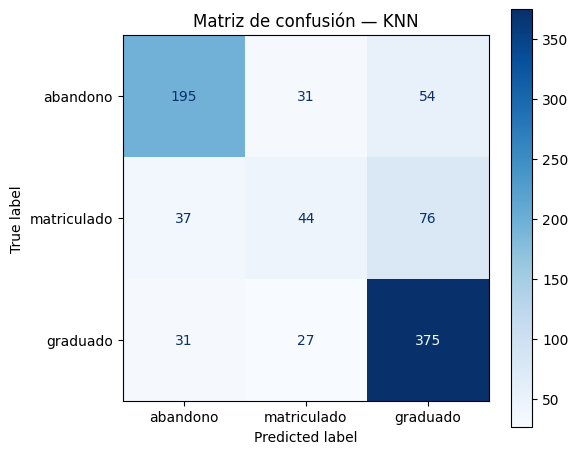

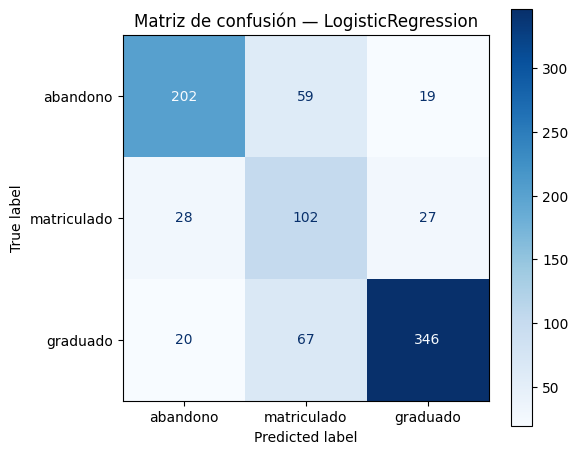

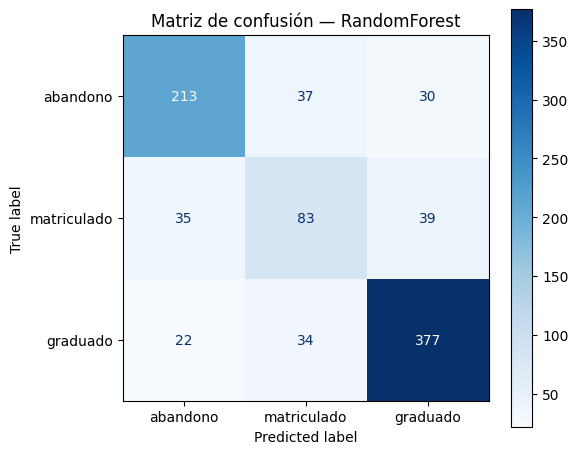

In [25]:
for nombre, fig in figs_cm.items():
    display(fig)

**Lectura de las matrices.** Las filas son la clase real y las columnas la
predicha. La diagonal es correcto, lo de fuera son errores. Conviene fijarse en:

- **Confusiones `matriculado` ↔ `graduado`**: muy frecuentes porque ambos
  completaron el 1er semestre con rendimiento similar; lo único que los
  distingue es si en algún momento posterior completaron o no la titulación.
- **`abandono` bien separado**: sus variables académicas (nota 0, pocas
  asignaturas aprobadas) son muy distintivas, así que todos los modelos lo
  detectan con alta precisión.
- **Casos donde el modelo predice `abandono` pero es `graduado`**: son los
  falsos positivos más preocupantes desde el punto de vista institucional,
  porque llevarían a intervenciones innecesarias.

## 6. Importancia de variables (Random Forest)

El RF nos permite jerarquizar las variables por su contribución a la
reducción de impureza Gini a lo largo de todos los árboles.

,variable,importancia
0,asignaturas_2sem_aprobadas,0.130561
1,nota_media_2sem,0.108501
2,asignaturas_1sem_aprobadas,0.092897
3,nota_media_1sem,0.071229
4,nota_admision,0.037876
5,edad_al_matricularse,0.037741
6,matricula_al_dia_si,0.031697
7,nota_cualificacion_previa,0.030016
8,matricula_al_dia_no,0.029753
9,asignaturas_2sem_evaluadas,0.025153


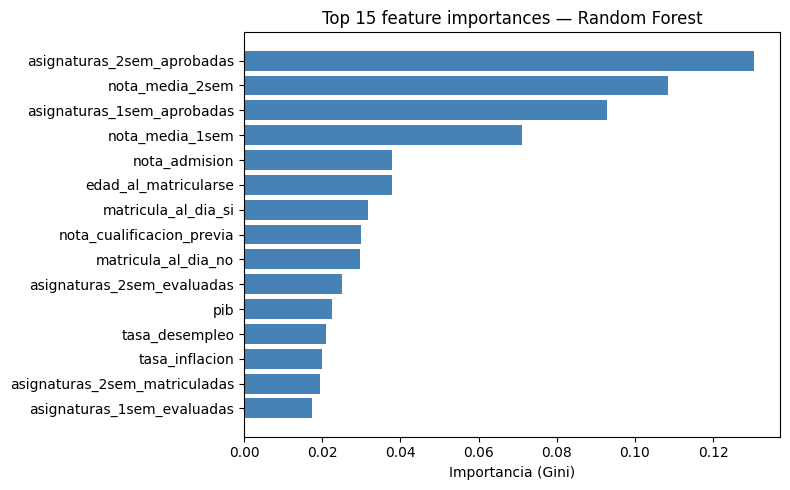

In [29]:
df_imp, fig_imp = clasificacion.importancia_variables(
    resultados['RandomForest'],
    top_n=15,
    path_fig=str(FEATURE_IMPORTANCE_CLF))

df_imp

**Interpretación.** Las variables de rendimiento del 2º semestre
(`nota_media_2sem`, `asignaturas_2sem_aprobadas`, `asignaturas_2sem_evaluadas`)
dominan la importancia, como era de esperar: el rendimiento del segundo semestre
es el predictor más fuerte de la trayectoria. Entre las no académicas destacan
`nota_admision`, `edad_al_matricularse` y como variable administrativa, `matricula_al_dia`,
asociadas al riesgo de abandono.

**Limitación:** la importancia de Gini está sesgada en presencia de
multicolinealidad (variables correladas se reparten la importancia de forma
arbitraria). Para una lectura más robusta se podría complementar con
permutation importance.

## 7. Guardar predicciones del mejor modelo

Elegimos el modelo con mayor F1 macro en test y guardamos sus predicciones
sobre test en un CSV para entregar.

In [30]:
nombre_mejor = df_resumen.loc[df_resumen['f1_macro_test'].idxmax(), 'modelo']
gs_mejor = resultados[nombre_mejor]
f1_mejor = df_resumen['f1_macro_test'].max()
print(f'Mejor modelo: {nombre_mejor}  (F1 macro test = {f1_mejor:.4f})')

preds = pd.DataFrame({
    'y_real': y_test.values,
    'y_pred': gs_mejor.predict(X_test),
})
preds.to_csv(PREDICCIONES_CLASIFICACION, index=False)
print(f'Guardado: {PREDICCIONES_CLASIFICACION}')
preds.head()

Mejor modelo: RandomForest  (F1 macro test = 0.7220)
Guardado: C:\Users\mb6ja\Downloads\proyecto\results\predicciones_clasificacion.csv


,y_real,y_pred
0,0,0
1,2,2
2,2,2
3,1,2
4,2,2


## 8. Conclusiones

- El **Random Forest** suele ser el modelo con mejor F1 macro en test,
  aprovechando las interacciones no lineales entre variables académicas y
  administrativas.
- La **regresión logística** queda muy cerca con mucha menos complejidad,
  ofreciendo gran interpretabilidad gracias a los pesos.
- **KNN** tiende a ser el más débil por la dimensionalidad después de aplicar el one-hot:
  con muchas variables categóricas, la noción de distancia se vuelve confusa
  (curse of dimensionality).
- La clase **`matriculado`** es la más difícil de todas por su posición
  intermedia entre abandono y graduación y por el menor número de instancias en el dataset.
- El rendimiento académico del **2º semestre** es el predictor dominante,
  seguido de señales administrativas de riesgo (deuda, matrícula al día).
  Esto sugiere que las intervenciones institucionales a lo largo del segundo semestre
  son el punto con mayor potencial de impacto.